### Problem statement
System: In -> A -> B -> C

<br>

**In $\rightarrow$ A:** Transform Qubit Readout data. Messages arrive with fixed mean arrival rate $\lambda$. Infinite queue if stage A blocked.

**A:** Read message. Processing time $\mathrm{Uniform}(1.5, 2.2)\mu s$.

**A $\rightarrow$ B:** FIFO buffer. Capacity = 100. If full A stops

**B:** Log-Normal distribution processing time $\mu = 0.5 , \sigma ^2 = 0.5$

**B $\rightarrow$ C:** FIFO buffer. Capacity = 25. If full B stops

**C:** Constant time of $1.5\mu s$

In [17]:
import numpy as np
import matplotlib.pyplot as plt

Num Qubits through system: 4822
Mean qubit times: 4547.5445240514355
Latency from enter A: 160.04991624613464
A utilisation:  0.98362179984468
B utilisation:  0.9996488998421754
C utilisation:  0.7233850998858123
Time stopped A:  0.05598859999052934
Time stopped B:  0.0


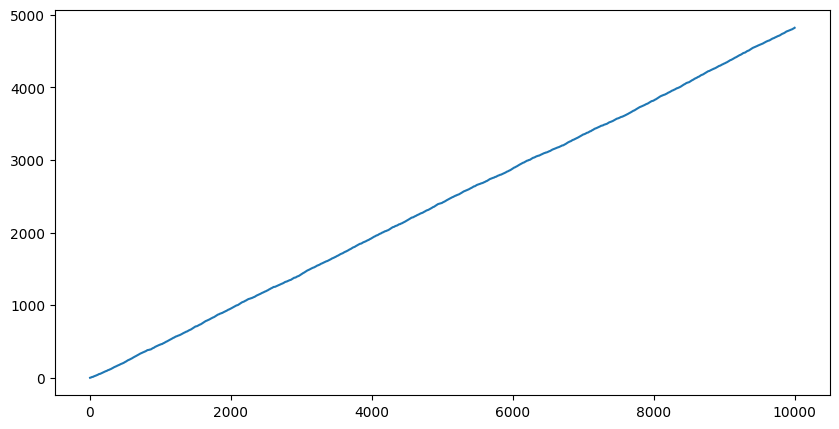

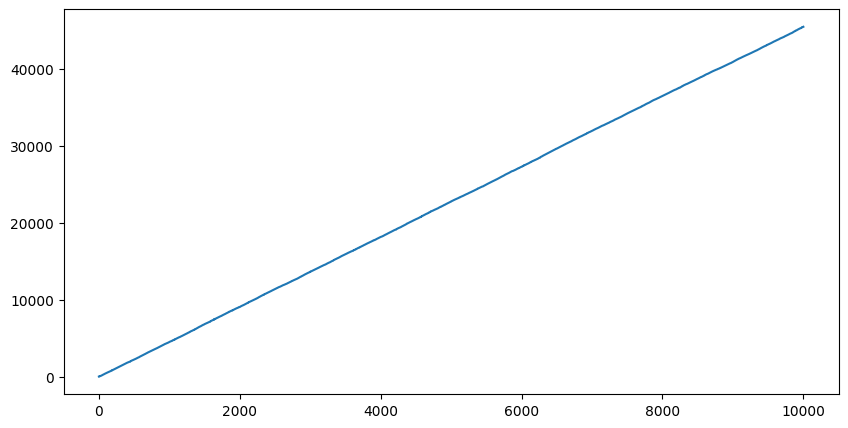

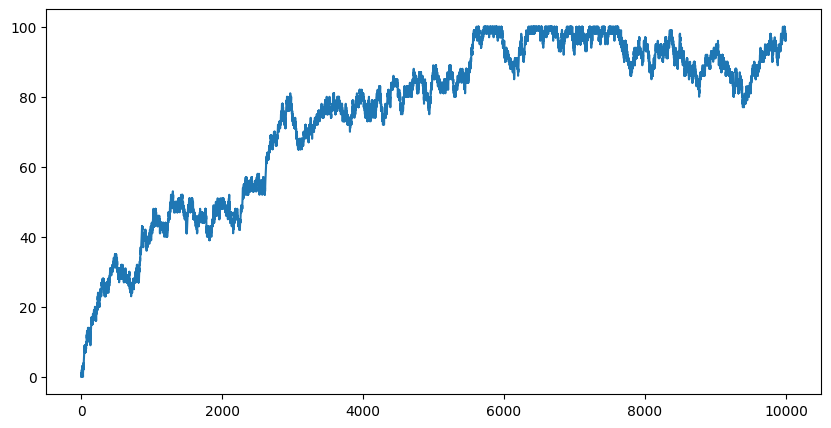

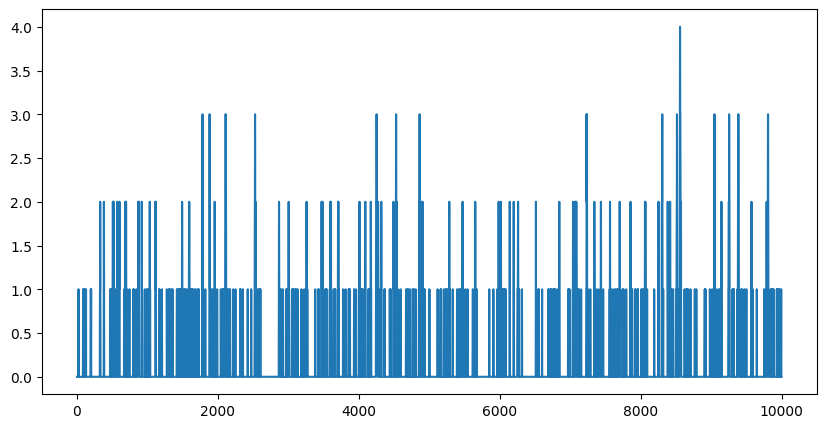

In [19]:
class Queue:
    def __init__(self, max_length):
        self.length = 0
        self.max_length = max_length

# TODO: Do not really need this to be a class at this point
class Source:
    def __init__(self, lam):
        self.lam = lam

    def next_arrival(self):
        return np.random.exponential(scale=self.lam)
    
# TODO: Look into why log-normal is much slower on average dispite having a  lower mean
def run_sim(lam, max_time):

    ts = 0.001
    max_time = max_time

    # All qubits assumed identical. Only need to keep track of queue length
    b_queue = Queue(100)
    c_queue = Queue(25)
    a_queue = Queue(1e8) # Could also be int
        
    source = Source(lam)

    # Initialise variables
    time = 0.0
    a_time = 0.0
    b_time = 0.0
    c_time = 0.0

    a_stopped = False
    b_stopped = False

    qubits_through_a = 0
    qubits_through_b = 0
    qubits_through_c = 0

    qubit_enter_a_times = []

    next_a_arrival = source.next_arrival()

    # To gather statistics
    callbacks = {
        'a_queue_lengths': [],
        'b_queue_lengths': [],
        'c_queue_lengths': [],
        'a_time_on': 0.0,
        'b_time_on': 0.0,
        'c_time_on': 0.0,
        'qubit_in_times': [],
        'latency_from_a': 0,
        'qubit_out_times': [],
        'final_queue_lengths': [0, 0, 0],
        'total_time': 0,
        'component_utilisation': {},
        'mean_time_in_system': 0,
        'times_in_system': [],
        'time_stopped_a': 0,
        'time_stopped_b': 0,
    }

    while time < max_time:
        
        # Qubit enters the system. Enters queue into A
        if next_a_arrival < ts:
            a_queue.length += 1

            next_a_arrival = source.next_arrival()

            callbacks['qubit_in_times'] += [time]
            callbacks['a_queue_lengths'] += [(a_queue.length, time)]

        # Qubit enters A. Sample from Uniform distribution to determine time spent in A
        if (a_queue.length > 0) and (a_time < ts) and (not a_stopped):
            
            # Handles time at > 3 decimal places (np.random generates floats with higher percision. Some residual left when a_time < ts)
            extra_time = a_time

            # Use to ensure qubit doesn't exit A when initial qubit enters
            qubits_through_a += 1

            a_queue.length -= 1

            # Processing time for this qubit
            a_time = np.random.random() + 1.5

            # Gather statistics
            callbacks['a_time_on'] += (a_time - extra_time)
            qubit_enter_a_times += [time]
            callbacks['a_queue_lengths'] += [(a_queue.length, time)]

            # Add to B que ue if not at capacity. 
            if (b_queue.length < b_queue.max_length) and (qubits_through_a > 1):
                b_queue.length += 1
                callbacks['b_queue_lengths'] += [(b_queue.length, time)]

                # If this causes B queue to reach capacity pause system A, preventing other qubits entering
                if b_queue.length == b_queue.max_length:
                    a_stopped = True

        # Qubits enter B, Sample from lognormal distribution to determine time
        if (b_queue.length > 0) and (b_time < ts) and (not b_stopped):

            # Unpause system A when queue space frees up
            a_stopped = False

            # Handles time at >3 decimal places
            extra_time = b_time

            # Same as A
            qubits_through_b += 1

            b_queue.length -= 1

            b_time = np.random.lognormal(mean=0.5, sigma=np.sqrt(0.5))

            callbacks['b_queue_lengths'] += [(b_queue.length, time)]
            callbacks['b_time_on'] += (b_time - extra_time)

            # Same as A
            if (c_queue.length < c_queue.max_length) and (qubits_through_b > 1):
                c_queue.length += 1
                # callbacks['c_queue_lengths'] += [(c_queue.length/, time)]

                # Same as A
                if c_queue.length == c_queue.max_length:
                    b_stopped = True


        if (c_queue.length > 0) and (c_time < ts):
            b_stopped = False

            qubits_through_c += 1
            c_queue.length -= 1

            c_time = 1.5
            
            callbacks['c_queue_lengths'] += [(c_queue.length, time)]
            callbacks['c_time_on'] += 1.5

            if qubits_through_c > 1:
                # Deterministic time: 1.5 micros. No residuals
                callbacks['qubit_out_times'] += [time]

        # Step time
        time += ts
        next_a_arrival -= ts
        if a_time > 0:
            a_time -= ts
        if b_time > 0:
            b_time -= ts
        if c_time > 0:
            c_time -= ts

        if a_stopped:
            callbacks['time_stopped_a'] += ts
        if b_stopped:
            callbacks['time_stopped_b'] += ts

    # Calculate and store statistics
    callbacks['final_queue_lengths'][0] = a_queue.length
    callbacks['final_queue_lengths'][1] = b_queue.length
    callbacks['final_queue_lengths'][2] = c_queue.length

    callbacks['a_time_on'] -= a_time
    callbacks['b_time_on'] -= b_time
    callbacks['c_time_on'] -= c_time

    callbacks['decoding_rate'] = len(callbacks['qubit_out_times'])/time

    callbacks['component_utilisation']['a'] = callbacks['a_time_on']/time
    callbacks['component_utilisation']['b'] = callbacks['b_time_on']/time
    callbacks['component_utilisation']['c'] = callbacks['c_time_on']/time

    callbacks['times_in_system'] = [(callbacks['qubit_out_times'][i] - callbacks['qubit_in_times'][i]) for i in range(len(callbacks['qubit_out_times']))]
    callbacks['mean_time_in_system'] = np.mean(callbacks['times_in_system'])
    callbacks['latency_from_a'] = np.mean([(callbacks['qubit_out_times'][i] - qubit_enter_a_times[i]) for i in range(len(callbacks['qubit_out_times']))])

    callbacks['time_stopped_a'] = callbacks['time_stopped_a']/time
    callbacks['time_stopped_b'] = callbacks['time_stopped_b']/time

    return callbacks

callbacks = run_sim(0.2, 10000)

print('Num Qubits through system:', len(callbacks['qubit_out_times']))

print('Mean qubit times:', callbacks['mean_time_in_system'])
print('Latency from enter A:', callbacks['latency_from_a'])

print('A utilisation: ', callbacks['component_utilisation']['a'])
print('B utilisation: ', callbacks['component_utilisation']['b'])
print('C utilisation: ', callbacks['component_utilisation']['c'])

print('Time stopped A: ', callbacks['time_stopped_a'])
print('Time stopped B: ', callbacks['time_stopped_b'])


fig = plt.figure(figsize = (10, 5))
plt.plot(callbacks['qubit_out_times'], range(1, len(callbacks['qubit_out_times'])+1))
plt.show()

y, x = zip(*callbacks['a_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

y, x = zip(*callbacks['b_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

y, x = zip(*callbacks['c_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()


## Comments

1. B seems to be bottleneck. Everything downstream is clear
2. Maybe worth doing a plot explainig how B maxing out affects A
3. Final throughput/sec should be ~1/lambda until bottleneck appears. Plot of 1/lambda vs throughput/sec
4. May be worth doing mean time from when they enter A as opposed to when they enter the queue

In [8]:
len(callbacks['qubit_in_times']), len(callbacks['qubit_out_times']), callbacks['final_queue_lengths'][0], callbacks['final_queue_lengths'][1], callbacks['final_queue_lengths'][2]

(50289, 4752, 45447, 87, 0)

In [ ]:
test_no = 30
lams = [0.5, 1.0, 1.5, 1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 3.0, 3.5, 4.0, 4.5]
latency_from_a_means = [[],[]]
total_latency_means = [[],[]]
decoding_rate = [[],[]]

a_utilisation_means = []
b_utilisation_means = []
c_utilisation_means = []

a_queue_length_means = []
b_queue_length_means = []
c_queue_length_means = []

time_stopped_a_means = []
time_stopped_b_means = []

# TODO: Investigate queue lengths
for lam in lams:

    latencies_from_a = []
    total_latencies = []
    decoding = []

    a_utilisation = []
    b_utilisation = []
    c_utilisation = []

    a_queue_length = []
    b_queue_length = []
    c_queue_length = []

    time_stopped_a = []
    time_stopped_b = []

    for _ in range(test_no):
        results = run_sim(lam, 10000)

        # Gather results for given value of lambda
        latencies_from_a.append(results['latency_from_a'])
        total_latencies.append(results['mean_time_in_system'])
        decoding.append(results['decoding_rate'])

        a_utilisation.append(results['component_utilisation']['a'])
        b_utilisation.append(results['component_utilisation']['b'])
        c_utilisation.append(results['component_utilisation']['c'])

        a_queue_length.append(np.mean(list(zip(*results['a_queue_lengths']))[0]))
        b_queue_length.append(np.mean(list(zip(*results['b_queue_lengths']))[0]))
        c_queue_length.append(np.mean(list(zip(*results['c_queue_lengths']))[0]))

        time_stopped_a.append(results['time_stopped_a'])
        time_stopped_b.append(results['time_stopped_b'])

    # Calculate means for each run
    latency_from_a_means[0].append(np.mean(latencies_from_a))
    latency_from_a_means[1].append(np.std(latencies_from_a))

    total_latency_means[0].append(np.mean(total_latencies))
    total_latency_means[1].append(np.std(total_latencies))
    
    decoding_rate[0].append(np.mean(decoding))
    decoding_rate[1].append(np.std(decoding))

    a_utilisation_means.append(np.mean(a_utilisation))
    b_utilisation_means.append(np.mean(b_utilisation))
    c_utilisation_means.append(np.mean(c_utilisation))

    a_queue_length_means.append(np.mean(a_queue_length))
    b_queue_length_means.append(np.mean(b_queue_length))
    c_queue_length_means.append(np.mean(c_queue_length))

    time_stopped_a_means.append(np.mean(time_stopped_a))
    time_stopped_b_means.append(np.mean(time_stopped_b))



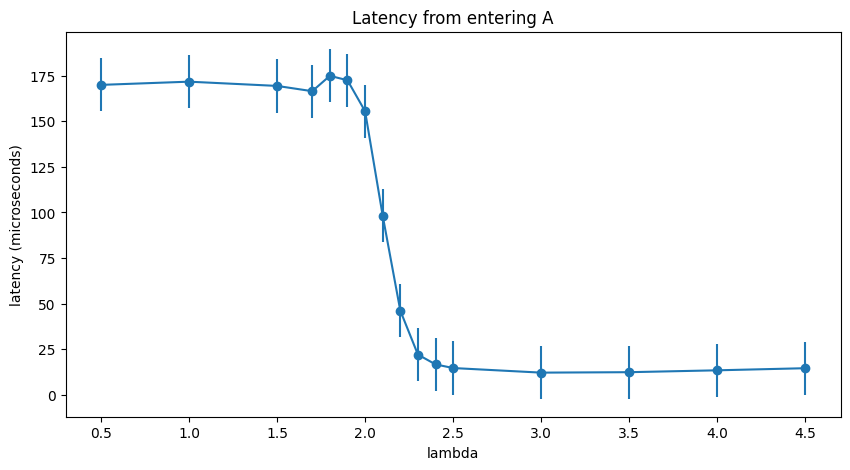

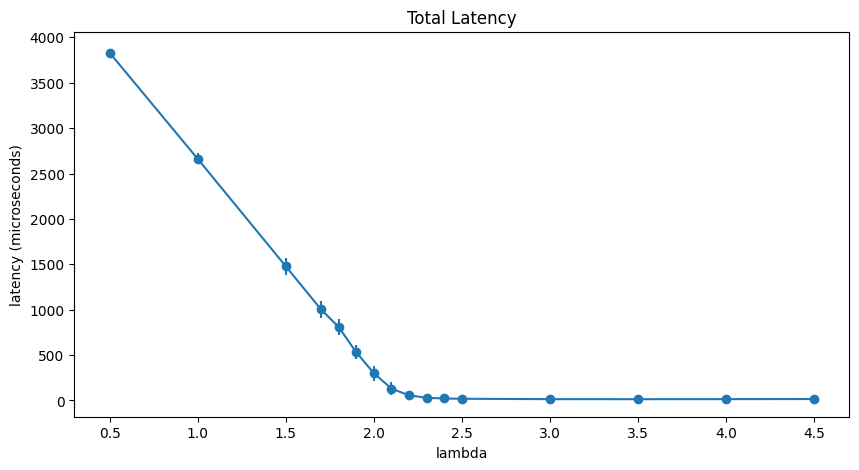

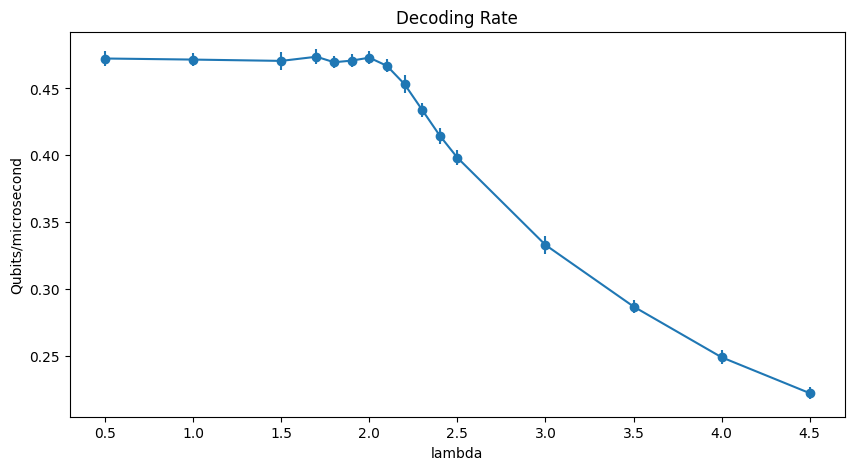

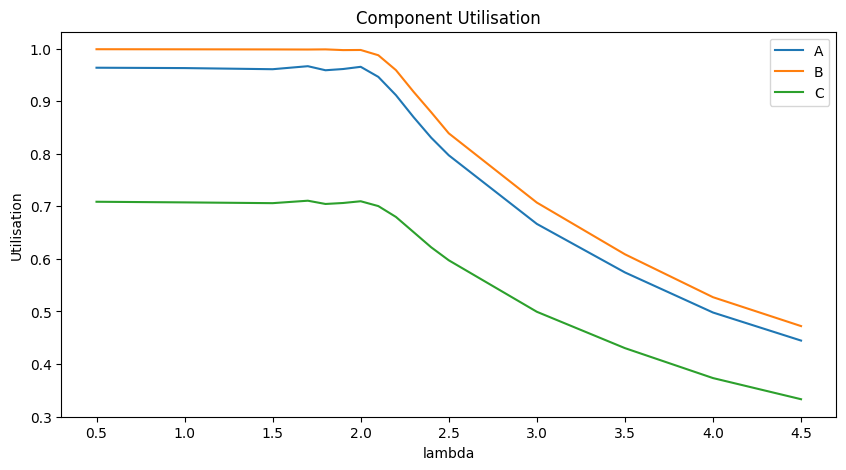

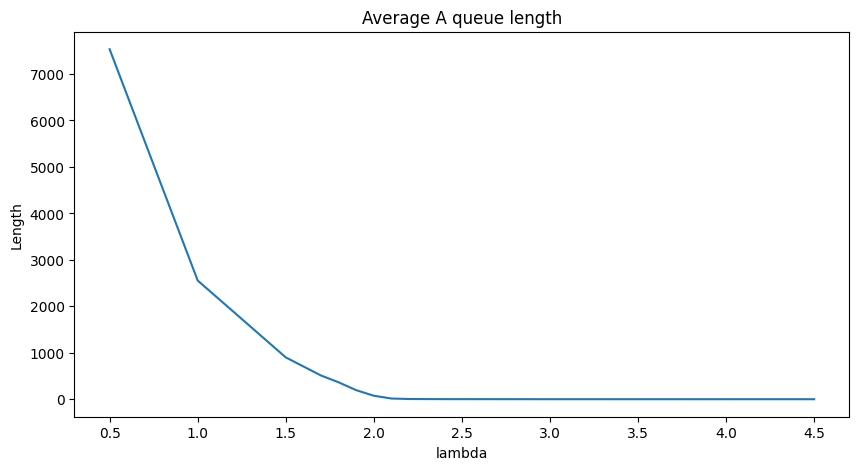

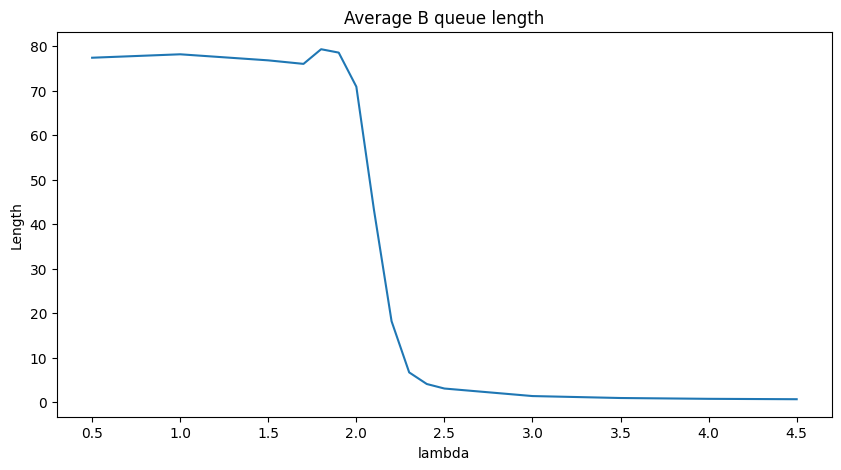

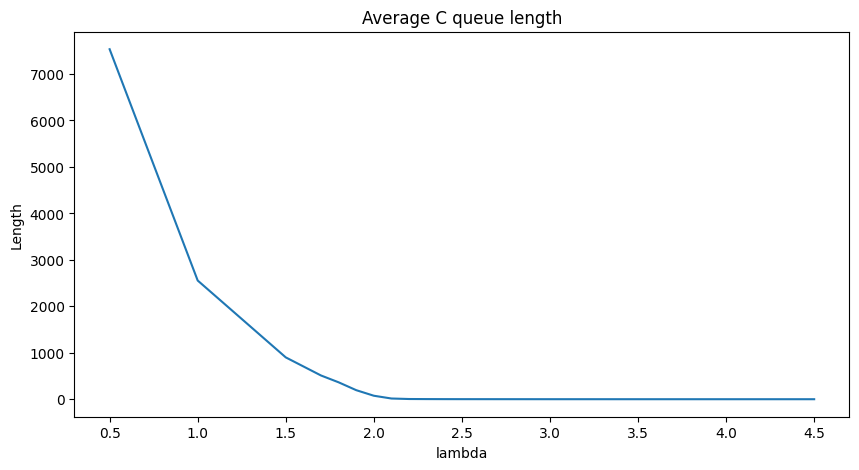

[np.float64(7533.776321577961), np.float64(2555.3067725394476), np.float64(900.9974107463485), np.float64(511.73220798535596), np.float64(364.7409720087783), np.float64(195.49259581720932), np.float64(75.68561848438493), np.float64(16.018544811576056), np.float64(5.20468653199443), np.float64(3.5361088373720304), np.float64(2.5559926573824256), np.float64(2.0593764999708912), np.float64(1.1729739614576598), np.float64(0.8890177662542883), np.float64(0.7501885314212602), np.float64(0.6877899073140902)]


In [ ]:
fig = plt.figure(figsize = (10, 5))
plt.errorbar(lams, latency_from_a_means[0], latencies_from_a[1], fmt='-o')
plt.title('Latency from entering A')
plt.xlabel('lambda')
plt.ylabel('latency (microseconds)')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.errorbar(lams, total_latency_means[0], total_latency_means[1], fmt='-o')
plt.title('Total Latency')
plt.xlabel('lambda')
plt.ylabel('latency (microseconds)')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.errorbar(lams, decoding_rate[0], decoding_rate[1], fmt='-o')
plt.title('Decoding Rate')
plt.xlabel('lambda')
plt.ylabel('Qubits/microsecond')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, a_utilisation_means, label='A')
plt.plot(lams, b_utilisation_means, label='B')
plt.plot(lams, c_utilisation_means, label='C')
plt.title('Component Utilisation')
plt.xlabel('lambda')
plt.ylabel('Utilisation')
plt.legend()
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, a_queue_length_means)
plt.title('Average A queue length')
plt.xlabel('lambda')
plt.ylabel('Length')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, b_queue_length_means)
plt.title('Average B queue length')
plt.xlabel('lambda')
plt.ylabel('Length')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, c_queue_length_means)
plt.title('Average C queue length')
plt.xlabel('lambda')
plt.ylabel('Length')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, time_stopped_a_means)
plt.title('Average portion  stopped: Component A')
plt.xlabel('lambda')
plt.ylabel('stopped portion')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, time_stopped_b_means)
plt.title('Average portion  stopped: Component B')
plt.xlabel('lambda')
plt.ylabel('stopped portion')
plt.show()

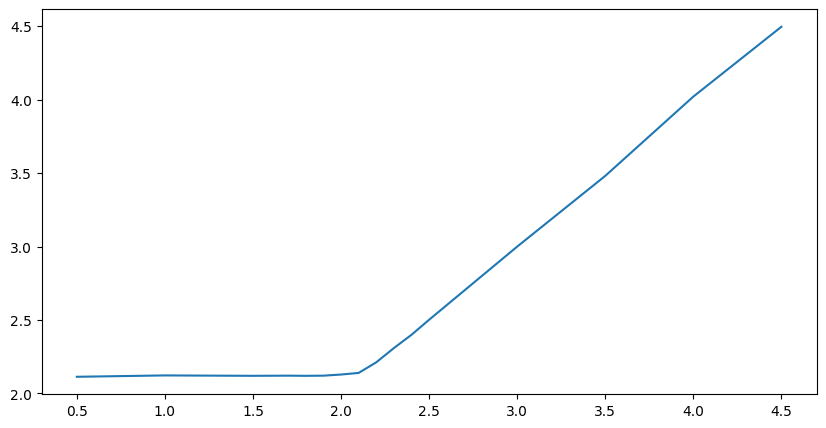

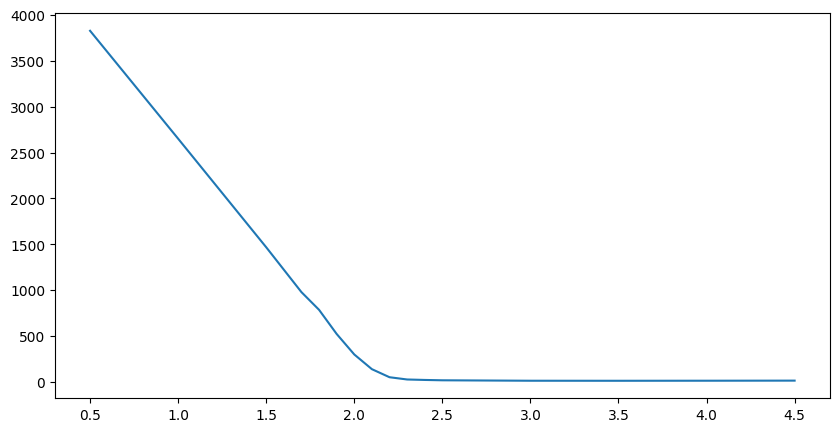

In [ ]:
fig = plt.figure(figsize = (10, 5))
plt.plot(lams, [1/x for x in decoding_rate])
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, total_latency_means)
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, total_latency_means)
plt.show()

### Method
Created a discrete event simulation of the systems. I defined a timestep in the system as $0.001\mu s$. This parameter can be changed at the cost of runtime if we wish to make the simulation more granular. t ~ $1/ts$. All logic is executed before stepping the clock at each ts.

Qubits enter and leave the queues by increasing or decreasing the length property of the respective queues. I do not model the FIFO nature of the queues as we are not concerned with distingushing messages, only higher level system/component statistics.

Qubits can enter a particular component if there are qubits in its queue and it is not blocked by queues in front of it

Qubits enter or leave components when the timer for each component reaches within one timestep

We can easily collect a wide range of data as the simulation runs, allowing us gather overall system and component statistics

### Asumptions
1. Queues are unordered. Focus on throughput as opposed to specific information encoded.
2. Systems and queues initially empty. Max throughputs/utilistaions may be slightly higher due to this
3. Time to travel between components is zero

### Validation
Did tests to keep track of all qubits within system. Need to have

```python
qubits_in = qubits_out
            qubits_in_queues + # qubits in each queue
            qubits_in_components + # Max one in each component
```

Having decoding rate ~ $1/\lambda$ for largrer values of lambda

### Results & Analysis

The simulation can be used with different input parameters to to investigate how these different parameters might change the system. As the sim in not deterministic, I ran multiple runs to get averages and deviations/variance.

The maximum decoding rate (throughput) is ~0.47qubits/microsecond. For many values of lambda this corresponds with A queue lengths infinitely growing. This rate begins to drop around $\lambda = 2.1\mu s$. As we continue to increase $\lambda$ this throughput scales as $1/\lambda$. This is expected for stable queue lengths as qubits_in = qubits_out.

Throughout all values of lambda, the utilisation of component B is highest, followed by utilisation of A, and then that of C. As we increase $\lambda$, component B becomes a bottleneck. Utilisation of C is consistently lower, with processing times much lower than teh averages of b and c

The latency for low values of lambda is very high. This reflects the long times qubits spend in queues at A as it grows infinitely. Even for constant values of $\lambda$, total latency will not stabilise, as qubits wait longer as the A queue length increases. Decreasing the value of $\lambda$ decreases the rate at which this que grows, but does not allow the queue to stabilise until $\lambda = 2.1$. We can also examine times as from when qubits enter component A. For low values of $\lambda$ there is a constant time in the system of ~$170\mu s$. This reflects times when the B queue is at capacity. As long as the B queue is operating close to capacity, changes in $\lambda$ will have no effect of most high level statistics (utilisations, decoding rate, etc), instead the only factor that changes is the rate of growth of the A queue

As we increase $\lambda$ to roughly $2.1 - 2.2\mu s$ we reach a point where the queues at B start to stabilise, as opposed to staying at capacity. Avertage queue length for B drops dramatically and  This Means that component A does not spend time blocked, and the A queue also stabilises. This is the ideal maximum operating rate. Latencies drop dramatically to ~ $15\mu s$ as queues shorten. Although queues are not infinitely growing, we still see B is the bottleneck at these values of lambda, as the queue lengths for C remain very low.

As $\lambda$ continues above 2.5, A, and B queue lengths continue to fall until they are empty for the majority of the time. Qubits entering the system do not need to spend much time queueing, or for larger values of $\lambda$, they spend no time at all. Decoding rate becomes ~ $1/\lambda$, as the lack of backlogs means there is a stable flow of qubits through the system. Utilisation for all components drops as the system regulary completely clears itself of qubits before new ones enter the system.  As $\lambda \rightarrow \infty$ we expect average queue lengths to go towards zero, and latency drops to the sum of the means of the component processing times.